# 03 – Események és eseményablakok

Ebben a notebookban minden (cikk, ticker) párból eseményt készítek, és az esemény ablakaiban összegzem a 01. notebook perces mutatóit. Így minden eseményre megkapom, hogy a megjelenés után a papír árfolyama és forgalma mennyivel tért el a megszokottól. Az eseményeket a 04. notebook teszteli.

**Bemenet:** `perc_idosor.parquet` (01. notebook), `regi_hir.parquet` (02. notebook, az algoritmus osztálya cikk×ticker páronként) és a dokumentumok megjelenési ideje az adatbázis `dokumentum` táblájából.

**Kimenet:** `adat/cache/esemeny.parquet`, soronként egy (cikk, ticker) esemény.

**A mutatók** az $i$-edik eseményre, a $[t_1,t_2]$ ablakban. A hozamalapú mutatók bázispontban (bp) szerepelnek; 1 bp = 0,01%, a loghozam 10 000-szerese.

| oszlop | képlet | jelentése |
|---|---|---|
| `ccaar_kezdeti`, `ccaar_kesl` | $CCAAR_{i,t_1,t_2}=\sum_{t=t_1}^{t_2}CAAR_{i,t}$ (bp) | kumulált korrigált abszolút abnormális hozam |
| `ccaar_nyers_kezdeti` | ugyanez a nem kiigazított hozammal (bp) | robusztussági változat |
| `cavlog_kezdeti` | $CAVlog_i=\ln\frac{\sum_t V_{i,t}+1}{\sum_t \overline{V}_{i,\tau,d}+1}$ | a forgalom fő mutatója |
| `cav_kezdeti` | $CAV_{i,t_1,t_2}=\sum_{t=t_1}^{t_2}AV_{i,t}$ (darab) | a forgalom robusztussági mutatója |

| szakasz | tartalom |
|---|---|
| 0 | beállítások |
| 1 | betöltés |
| 2 | az ablakok és az események felépítése |
| 3 | az események megoszlása és teljessége |
| 4 | átfedő események |
| 5 | átlagos mutatók és eseményidő-profil |
| 6 | mentés |

## 0. Beállítások

In [1]:
import os
import sqlite3
from pathlib import Path
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

PROJEKT = Path(r"C:\Users\User\Desktop\BGE Szakdolgozat")
DB = PROJEKT / "adat" / "korpusz.sqlite"
CACHE = Path(os.environ.get("CACHE_MAPPA", PROJEKT / "adat" / "cache"))
IZ = ZoneInfo("Europe/Budapest")


def db_olvas(sql):
    con = sqlite3.connect(f"file:{DB.as_posix()}?mode=ro", uri=True)
    try:
        return pd.read_sql(sql, con)
    finally:
        con.close()


from bisect import bisect_left
from collections import Counter

| paraméter | jelentése | értéke |
|---|---|---|
| `PERC_KEZDET`, `PERC_VEG` | a perces rács első és utolsó perce (01. notebook) | 540 (09:00), 1020 (17:00) |
| `KEZDETI` | a kezdeti ablak hossza ($t_0+1\dots t_0+30$) | 30 perc |
| `KESLELTETETT` | a késleltetett ablak hossza ($t_0+31\dots t_0+120$) | 90 perc |
| `BP` | szorzó a bázispontba váltáshoz | 10 000 |

In [2]:
PERC_KEZDET = 9 * 60
PERC_VEG = 17 * 60
N = PERC_VEG - PERC_KEZDET + 1
KEZDETI = 30
KESLELTETETT = 90
BP = 10_000

## 1. Betöltés

A perces idősort papíronként (nap × perc) mátrixokba rendezem, így egy esemény ablaka egyszerű szeleteléssel kivehető. A cikkekhez az algoritmus osztályát (`uj`, `atvetel`, `ujrakombinalt`) a `regi_hir.parquet`-ből, a megjelenési időt az adatbázisból veszem.

In [3]:
perc = pd.read_parquet(CACHE / "perc_idosor.parquet").sort_values(["ticker", "nap", "perc"])
napok = sorted(perc.nap.unique())
D = len(napok)
assert perc.perc.nunique() == N

MUTATOK = ["CAAR", "R_kor", "V", "V_bazis", "AV"]
M = {}
for ticker, resz in perc.groupby("ticker"):
    M[ticker] = {mutato: resz[mutato].to_numpy().reshape(D, N) for mutato in MUTATOK}

hirek = pd.read_parquet(CACHE / "regi_hir.parquet", columns=["doc_id", "ticker", "forras", "osztaly"])
hirek = hirek.merge(db_olvas("SELECT doc_id, megjelenes_utc FROM dokumentum"), on="doc_id")
hirek = hirek.sort_values("megjelenes_utc", kind="stable").reset_index(drop=True)

print(f"{D} kereskedési nap, {len(M)} papír, {len(hirek)} cikk×ticker pár ({hirek.doc_id.nunique()} dokumentum)")

495 kereskedési nap, 4 papír, 7706 cikk×ticker pár (3713 dokumentum)


## 2. Az ablakok és az események felépítése

**Két eseményablak.** A kezdeti ablak ($t_0+1\dots t_0+30$ perc) lefedi a szakirodalomban (Kovács, 2017) mért kb. 20 perces beépülést. A késleltetett ablak ($t_0+31\dots t_0+120$ perc) azt mutatja, marad-e hatás a beépülés után.

*A módszer lényege:* a $t_0$ a megjelenés perce. A BÉT-közlemények és a Portfolio-cikkek megjelenési ideje percre pontos (a Telexé másodpercre), ezért nem tudható, hogy a dokumentum a percen belül mikor jelent meg, és a $t_0$ percének hozama részben még a megjelenés előtti lehet. Az ablak ezért a $t_0$ utáni perccel kezdődik. Az ablakok a nap végén (17:00) megállnak, ilyenkor a késleltetett ablak rövidebb (a hossza a `kesl_percek` oszlopban van).

**Nyitvatartáson kívüli megjelenés.** Ha a dokumentum nem a 09:00–17:00 közötti időben jelenik meg, a hatás csak a következő kereskedési perctől mérhető, ezért az ablak a 09:00-s perccel kezdődik. A `t0_tipus` négy értéke:

| `t0_tipus` | megjelenés | az ablak kezdete |
|---|---|---|
| `nyitvatartas` | kereskedési napon, 09:00 és 17:00 között | a $t_0$ utáni perc |
| `nyitas_elott` | kereskedési napon, 09:00 előtt | ugyanazon a napon 09:00 |
| `zaras_utan` | kereskedési napon, 17:00 után | a következő kereskedési napon 09:00 |
| `szunnap` | hétvégén vagy ünnepnapon | a következő kereskedési napon 09:00 |

Az utóbbi három esetben a 09:00-s perc hozama az éjszakai rést is tartalmazza, ami nem rendelhető egyetlen hírhez. Az eseményt eldobom, ha a 30 perces kezdeti ablak már nem fér bele a napba (a $t_0$ 16:30 utáni), vagy ha nincs következő kereskedési nap az adatban.

**A forgalom logaritmikus aránya.** A négy papír percforgalma nagyságrendekkel eltér, ezért a darabban mért CAV-ot a nagy forgalmú papírok uralnák. A tényleges és a bázisforgalom aránya papírtól független, a logaritmus pedig szimmetrikussá teszi: a kétszeres és a feleakkora forgalom ugyanakkora, ellentétes előjelű értéket kap. A $+1$ azért kell, hogy kötés nélküli ablaknál se kelljen nulla logaritmusát venni.

In [4]:
def ablak_kezdete(helyi_ido):
    nap = helyi_ido.strftime("%Y-%m-%d")
    perc_nap = helyi_ido.hour * 60 + helyi_ido.minute
    d = bisect_left(napok, nap)
    kereskedesi_nap = d < D and napok[d] == nap
    if kereskedesi_nap and PERC_KEZDET <= perc_nap <= PERC_VEG:
        return "nyitvatartas", d, perc_nap + 1
    if kereskedesi_nap and perc_nap < PERC_KEZDET:
        return "nyitas_elott", d, PERC_KEZDET
    if kereskedesi_nap:
        return "zaras_utan", d + 1, PERC_KEZDET
    return "szunnap", d, PERC_KEZDET


def osszeg(matrix, d, szelet):
    ertekek = matrix[d, szelet]
    return ertekek.sum() if len(ertekek) > 0 else np.nan

In [5]:
sorok = []
caar_profil = []
av_profil = []
eldobva = Counter()
helyi_idok = pd.to_datetime(hirek.megjelenes_utc, utc=True).dt.tz_convert(IZ)

for hir, helyi_ido in zip(hirek.itertuples(index=False), helyi_idok):
    tipus, d, kezdo_perc = ablak_kezdete(helyi_ido)
    if d >= D:
        eldobva["nincs következő kereskedési nap"] += 1
        continue
    i0 = kezdo_perc - PERC_KEZDET
    if i0 + KEZDETI > N:
        eldobva["a kezdeti ablak nem fér bele a napba"] += 1
        continue

    m = M[hir.ticker]
    kezdeti = slice(i0, i0 + KEZDETI)
    kesl = slice(i0 + KEZDETI, min(i0 + KEZDETI + KESLELTETETT, N))
    teljes = slice(i0, min(i0 + KEZDETI + KESLELTETETT, N))

    sorok.append({
        "doc_id": hir.doc_id,
        "ticker": hir.ticker,
        "forras": hir.forras,
        "osztaly": hir.osztaly,
        "t0_utc": hir.megjelenes_utc,
        "t0_perc": helyi_ido.hour * 60 + helyi_ido.minute,
        "t0_tipus": tipus,
        "nap": napok[d],
        "kezdo_perc": kezdo_perc,
        "kesl_percek": kesl.stop - kesl.start,
        "ccaar_kezdeti": BP * osszeg(m["CAAR"], d, kezdeti),
        "ccaar_kesl": BP * osszeg(m["CAAR"], d, kesl),
        "ccaar_nyers_kezdeti": BP * osszeg(m["R_kor"], d, kezdeti),
        "cav_kezdeti": osszeg(m["AV"], d, kezdeti),
        "cavlog_kezdeti": np.log((osszeg(m["V"], d, kezdeti) + 1) / (osszeg(m["V_bazis"], d, kezdeti) + 1)),
    })

    caar = np.full(KEZDETI + KESLELTETETT, np.nan)
    av = np.full(KEZDETI + KESLELTETETT, np.nan)
    hossz = teljes.stop - teljes.start
    caar[:hossz] = BP * m["CAAR"][d, teljes]
    av[:hossz] = m["AV"][d, teljes]
    caar_profil.append(caar)
    av_profil.append(av)

esemeny = pd.DataFrame(sorok)
caar_profil = np.array(caar_profil)
av_profil = np.array(av_profil)

print(f"{len(esemeny)} esemény {esemeny.doc_id.nunique()} dokumentumból; eldobva: {dict(eldobva)}")
esemeny.head()

7647 esemény 3657 dokumentumból; eldobva: {'a kezdeti ablak nem fér bele a napba': 52, 'nincs következő kereskedési nap': 7}


,doc_id,ticker,forras,osztaly,t0_utc,t0_perc,t0_tipus,nap,kezdo_perc,kesl_percek,ccaar_kezdeti,ccaar_kesl,ccaar_nyers_kezdeti,cav_kezdeti,cavlog_kezdeti
0,7944478299f381f7b3b2,OTP,portfolio,uj,2024-01-02T05:00:00Z,360,nyitas_elott,2024-01-02,540,90,NaN,NaN,NaN,NaN,NaN
1,7944478299f381f7b3b2,MOL,portfolio,uj,2024-01-02T05:00:00Z,360,nyitas_elott,2024-01-02,540,90,NaN,NaN,NaN,NaN,NaN
2,7944478299f381f7b3b2,RICHTER,portfolio,uj,2024-01-02T05:00:00Z,360,nyitas_elott,2024-01-02,540,90,NaN,NaN,NaN,NaN,NaN
3,7944478299f381f7b3b2,MTELEKOM,portfolio,uj,2024-01-02T05:00:00Z,360,nyitas_elott,2024-01-02,540,90,NaN,NaN,NaN,NaN,NaN
4,d69914b43ce8e008394b,OTP,portfolio,uj,2024-01-02T08:15:00Z,555,nyitvatartas,2024-01-02,556,90,NaN,NaN,NaN,NaN,NaN


**Eredmény.** A 7 706 cikk×ticker párból 7 647 esemény lett, 3 657 dokumentumból (egy cikk több papírról is szólhat). 59 párt dobtam el: 52-nél a kezdeti ablak már nem fért bele a napba (16:30 utáni megjelenés), 7-nél nem volt következő kereskedési nap.

## 3. Az események megoszlása és teljessége

A forrás és az algoritmus osztálya szerinti megoszlás azt mutatja, mekkora csoportok kerülnek a H1b összevetésébe. A $t_0$ típusa szerinti megoszlásból látszik, hány esemény ablaka tartalmazza az éjszakai rést.

In [6]:
print("Forrás × osztály:")
display(pd.crosstab(esemeny.forras, esemeny.osztaly, margins=True))
print("A t0 típusa × forrás:")
tipus_forras = pd.crosstab(esemeny.t0_tipus, esemeny.forras, margins=True)
tipus_forras["arány_%"] = (100 * tipus_forras.All / len(esemeny)).round(1)
display(tipus_forras)

Forrás × osztály:


osztaly,atvetel,uj,ujrakombinalt,All
forras,,,,
bet,0,1322,0,1322
portfolio,2580,1422,2065,6067
telex,62,170,26,258
All,2642,2914,2091,7647


A t0 típusa × forrás:


forras,bet,portfolio,telex,All,arány_%
t0_tipus,,,,,
nyitas_elott,544,174,63,781,10.2
nyitvatartas,631,2726,108,3465,45.3
szunnap,21,38,23,82,1.1
zaras_utan,126,3129,64,3319,43.4
All,1322,6067,258,7647,100.0


In [7]:
print(f"Van bázis (a ccaar_kezdeti nem üres): {esemeny.ccaar_kezdeti.notna().mean():.1%} "
      f"({esemeny.ccaar_kezdeti.isna().sum()} eseménynél nincs, ezek az első 21 kereskedési napra esnek)")
print(f"Teljes, 90 perces késleltetett ablak: {(esemeny.kesl_percek == KESLELTETETT).mean():.1%}; "
      f"rövidebb: {(esemeny.kesl_percek < KESLELTETETT).sum()} esemény, "
      f"ebből késleltetett ablak nélkül: {(esemeny.kesl_percek == 0).sum()}")

Van bázis (a ccaar_kezdeti nem üres): 94.9% (391 eseménynél nincs, ezek az első 21 kereskedési napra esnek)
Teljes, 90 perces késleltetett ablak: 98.1%; rövidebb: 143 esemény, ebből késleltetett ablak nélkül: 8


**Eredmény.** Forrás szerint 1 322 BÉT-, 6 067 Portfolio- és 258 Telex-esemény van; a BÉT-közlemények mind újak. Az események 45,3%-a (3 465) jelent meg nyitvatartás alatt, 43,4%-a (3 319) zárás után, 10,2%-a (781) nyitás előtt és 1,1%-a (82) szünnapon, vagyis több mint felük ablaka a következő nyitással, az éjszakai réssel kezdődik. 391 eseménynek (5,1%) nincs bázisa, mert az első 21 kereskedési napra esik. Az események 98,1%-ánál teljes a 90 perces késleltetett ablak; 143-nál rövidebb, ebből 8-nál a kezdeti ablak éppen a nap végéig tart, ezért késleltetett ablak nincs.

## 4. Átfedő események

**Az átfedés mérése.** Ha ugyanarról a papírról rövid időn belül több cikk jelenik meg, az ablakaik átfedik egymást, és az egyik cikk hatása a másik ablakába is beleszámít. Ilyenkor az események nem független megfigyelések, és az eseményszintű próbák túl kis p-értéket adnának. A 04. notebook ezért ticker-nap szinten (klaszterként) kezeli az eseményeket.

Papíronként időrendbe teszem az ablakok kezdetét, és megnézem, mennyi idő telt el az előző esemény ablakának kezdete óta (kereskedési percekben, a napokat egymás után fűzve).

In [9]:
nap_sorszam = {nap: i for i, nap in enumerate(napok)}

kezdet = esemeny[["ticker", "nap", "kezdo_perc"]].assign(
    abszolut_perc=lambda df: df["nap"].map(nap_sorszam) * N + (df["kezdo_perc"] - PERC_KEZDET)
).sort_values(["ticker", "abszolut_perc"])

eltelt = kezdet.groupby("ticker")["abszolut_perc"].diff()

print("Az ablak kezdete az előző, ugyanahhoz a papírhoz tartozó esemény ablakának kezdetétől számítva:")

feltetelek = [
    ("ugyanabban a percben", eltelt == 0),
    (f"{KEZDETI} percen belül", eltelt < KEZDETI),
    (f"{KEZDETI + KESLELTETETT} percen belül", eltelt < KEZDETI + KESLELTETETT),
]

for cimke, maszk in feltetelek:
    print(f"  {cimke}: {maszk.mean():.1%} ({maszk.sum()} esemény)")

Az ablak kezdete az előző, ugyanahhoz a papírhoz tartozó esemény ablakának kezdetétől számítva:
  ugyanabban a percben: 30.0% (2291 esemény)
  30 percen belül: 51.4% (3934 esemény)
  120 percen belül: 59.8% (4576 esemény)


**Eredmény.** Az események 30,0%-ánál (2 291) az ablak ugyanabban a percben indul, mint az ugyanahhoz a papírhoz tartozó előző eseményé, 51,4%-nál 30 percen belül, 59,8%-nál 120 percen belül. Az azonos percben induló ablakok 98,9%-a nyitvatartáson kívül megjelent cikkhez tartozik, ezeknél a következő nyitás az ablak kezdete, ezért azonos mutatóértéket kapnak.

## 5. Átlagos mutatók és eseményidő-profil

**Az átlagos kumulált mutatók.** Az $I$ eseményre átlagolva:

$$\mu(CCAAR_{t_1,t_2})=\frac{1}{I}\sum_{i=1}^{I}CCAAR_{i,t_1,t_2}, \qquad \mu(CAV_{t_1,t_2})=\frac{1}{I}\sum_{i=1}^{I}CAV_{i,t_1,t_2}$$

Ha a hír nagyobb kilengést okoz a hír nélküli szintnél, a $\mu(CCAAR)$ nullánál nagyobb. Az átlag mellé a mediánt is kiírom, mert a napon belüli hozamok eloszlása vastag farkú, és néhány nagy mozgás az átlagot elhúzhatja. A táblázat a bázissal rendelkező eseményeket tartalmazza, a $t_0$ típusa szerint, mert a nyitvatartáson kívüli események ablaka az éjszakai rést is tartalmazza. Ez leíró összevetés, próbát a 04. notebook végez.

In [10]:
bazissal = esemeny[esemeny.ccaar_kezdeti.notna()]
mutatok = ["ccaar_kezdeti", "ccaar_kesl", "cavlog_kezdeti", "cav_kezdeti"]
atlagok = bazissal.groupby("t0_tipus")[mutatok].agg(["mean", "median"]).round(2)
atlagok.insert(0, "n", bazissal.groupby("t0_tipus").size())
display(atlagok)

n ccaar_kezdeti        ccaar_kesl        cavlog_kezdeti        cav_kezdeti         
                            mean median       mean median           mean median        mean   median
t0_tipus                                                                                            
nyitas_elott   759         14.44   2.12      14.96 -16.86          -0.14  -0.15     7082.11 -3388.45
nyitvatartas  3257          1.29 -11.40       0.97 -23.47          -0.49  -0.42     1108.26 -4059.50
szunnap         82         89.15  37.72      18.06 -18.59           0.01  -0.10    16562.66 -1683.40
zaras_utan    3158          4.58 -24.16      -4.17 -36.76          -0.44  -0.44     2394.04 -5753.22

**Eredmény.** A nyitvatartás alatti események kezdeti CCAAR-jának átlaga 1,29 bp, mediánja −11,40 bp vagyis a tipikus cikk után az ár nem mozog a megszokottnál jobban, és a késleltetett ablakban (0,97 bp) sem. A nyitvatartáson kívülieknél az átlag nagyobb: zárás után 4,58 bp, nyitás előtt 14,44 bp, szünnapon 89,15 bp, mert az ablak az éjszakai rést is tartalmazza. Az átlag és a medián eltérő előjele azt mutatja, hogy az eloszlás jobbra ferde: néhány nagy kilengés felhúzza az átlagot. A medián azért negatív, mert a bázis a ferde eloszlás átlaga, és a tipikus perc kilengése kisebb az átlagnál. Ugyanezért negatív a kezdeti CAVlog mediánja is (nyitvatartás alatt −0,42).

**Eseményidő-profil.** Az átlagos korrigált abszolút abnormális hozam és az átlagos abnormális forgalom percenként, az ablak kezdetétől számítva:

$$\mu(CAAR_t)=\frac{1}{I}\sum_{i=1}^{I}CAAR_{i,t}, \qquad \mu(AV_t)=\frac{1}{I}\sum_{i=1}^{I}AV_{i,t}$$

A profilból látszik, hogy a hatás hány perc alatt cseng le. A nyitvatartás alatti és a nyitvatartáson kívüli eseményeket külön rajzolom, mert az utóbbiak első perce az éjszakai rést tartalmazza. A szaggatott vonal a kezdeti és a késleltetett ablak határa.

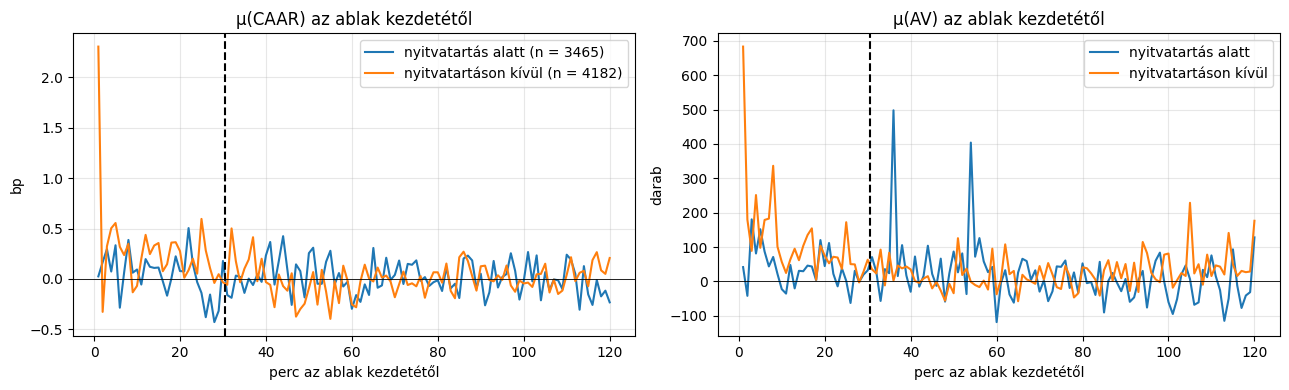

μ(CAAR) blokkonként (bp):


,nyitvatartás alatt,nyitvatartáson kívül
1. perc,0.026,2.306
2–5. perc,0.218,0.264
6–30. perc,0.016,0.193
31–120. perc,0.011,-0.001


In [11]:
nyitvatartas = (esemeny.t0_tipus == "nyitvatartas").to_numpy()
csoportok = {"nyitvatartás alatt": nyitvatartas, "nyitvatartáson kívül": ~nyitvatartas}
percek = np.arange(1, KEZDETI + KESLELTETETT + 1)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for nev, maszk in csoportok.items():
    ax[0].plot(percek, np.nanmean(caar_profil[maszk], axis=0), label=f"{nev} (n = {maszk.sum()})")
    ax[1].plot(percek, np.nanmean(av_profil[maszk], axis=0), label=nev)
ax[0].set_title("μ(CAAR) az ablak kezdetétől")
ax[0].set_ylabel("bp")
ax[1].set_title("μ(AV) az ablak kezdetétől")
ax[1].set_ylabel("darab")
for a in ax:
    a.axvline(KEZDETI + 0.5, color="k", ls="--")
    a.axhline(0, color="k", lw=0.6)
    a.set_xlabel("perc az ablak kezdetétől")
    a.legend()
plt.tight_layout()
plt.show()

blokkok = [("1. perc", 0, 1), ("2–5. perc", 1, 5), ("6–30. perc", 5, 30), ("31–120. perc", 30, 120)]
profil_tabla = pd.DataFrame({
    nev: {blokk: np.nanmean(caar_profil[maszk][:, a:b]) for blokk, a, b in blokkok}
    for nev, maszk in csoportok.items()
})
print("μ(CAAR) blokkonként (bp):")
display(profil_tabla.round(3))

**Eredmény.** Nyitvatartás alatt a μ(CAAR) az első percben 0,026 bp, a 2–5. percben 0,218 bp, a 6–30. percben 0,016 bp, a késleltetett ablakban 0,011 bp: a hatás néhány perc alatt lecseng, és a késleltetett ablakban átlagosan nem marad. A nyitvatartáson kívüli eseményeknél az első perc 2,306 bp, mert ez a 09:00-s perc az éjszakai réssel képződnek, ezt nem lehet értékelni.

## 6. Mentés

In [12]:
esemeny.to_parquet(CACHE / "esemeny.parquet", index=False)
print(f"Elmentve: esemeny.parquet ({len(esemeny)} sor)")

Elmentve: esemeny.parquet (7647 sor)
